# 02 · Data Audit

| | |
|---|---|
| **Question** | Can we trust this data enough to lend money on it? What exactly is wrong with it? |
| **Inputs** | `silver.stg_lending_club__loans`, `gold.mart_pd_features` |
| **Outputs** | Data quality scorecard (`reports/data_audit_scorecard.csv`) and a decision log that drives notebook 03 |
| **Skills shown** | Data quality framework, SQL-based profiling at scale, structural vs informative missingness, leakage detection |

### Audit framework

Every check falls into one of six dimensions. Each failing check gets a severity and a decision. Nothing is fixed silently.

| Dimension | Question |
|---|---|
| **Uniqueness** | Is every loan recorded once? |
| **Consistency** | Do related fields agree with each other? |
| **Validity** | Are values inside a plausible range? |
| **Completeness** | What is missing, and *why*? |
| **Timeliness** | How current is the data, and is every outcome mature? |
| **Leakage** | Could any field reveal the future to the model? |

All checks run as SQL inside DuckDB, so the audit scales to the full 2.26 million loans without loading them into memory.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from meridian import config, viz
from meridian.db import connect

viz.set_style()
con = connect()
REPORTS = config.PROJECT_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
audit_sql = (config.SQL_DIR / "audit" / "a01_validity_consistency.sql").read_text()

## 1. Uniqueness, consistency and validity

One SQL statement evaluates twelve rules over the full silver table. The query is in `sql/audit/a01_validity_consistency.sql`. One rule worth noting: the monthly instalment is recomputed from first principles with the annuity formula, $A = P \cdot \frac{r}{1-(1+r)^{-n}}$, and compared with the instalment Lending Club recorded.

In [2]:
total_loans = con.execute("select count(*) from silver.stg_lending_club__loans").fetchone()[0]
checks = con.execute(audit_sql).df()
checks["failing_share"] = checks.failing_rows / total_loans
checks.style.format({"failing_rows": "{:,.0f}", "failing_share": "{:.3%}"}).hide(axis="index")

dimension,rule,failing_rows,failing_share
validity,Debt-to-income is negative,2,0.000%
validity,Debt-to-income above 100% of income,"2,561",0.113%
validity,Annual income is zero or negative,"1,667",0.074%
validity,Annual income above USD 1M,583,0.026%
validity,Revolving utilisation above 150%,28,0.001%
validity,Home ownership coded ANY / NONE / OTHER,"1,232",0.054%
consistency,Funded amount above requested amount,0,0.000%
consistency,FICO low bound above high bound,0,0.000%
consistency,First credit line opened after the loan,0,0.000%
consistency,Instalment differs from annuity formula by more than 1%,714,0.032%


Uniqueness and consistency are excellent: no duplicate ids, no impossible FICO ranges, no credit histories that start after the loan. Two possible duplicate applications out of 2.26 million is noise.

The validity failures need a closer look. Are the zero incomes and the 999% debt-to-income ratios random errors, or a pattern?

In [3]:
con.execute("""
    select
        application_type,
        count(*)                                                       as loans,
        count(*) filter (where annual_income <= 0)                     as zero_income,
        count(*) filter (where annual_income <= 0 and annual_income_joint > 0) as zero_income_but_joint_income_present,
        count(*) filter (where debt_to_income > 1)                     as dti_above_100pct,
        median(debt_to_income_joint) filter (where debt_to_income > 1) as joint_dti_for_those_loans
    from silver.stg_lending_club__loans
    group by 1
""").df().style.format({"loans": "{:,.0f}", "zero_income": "{:,.0f}", "dti_above_100pct": "{:,.0f}",
                          "zero_income_but_joint_income_present": "{:,.0f}",
                          "joint_dti_for_those_loans": "{:.1%}"}).hide(axis="index")

application_type,loans,zero_income,zero_income_but_joint_income_present,dti_above_100pct,joint_dti_for_those_loans
individual,"2,139,958",0,0,0,nan%
joint app,"120,710","1,667","1,667","2,561",24.1%


**Finding:** every zero income and every DTI above 100% belongs to a **joint application**. Lending Club stores the household's income and DTI in separate `_joint` columns and leaves the individual ones empty or meaningless. This is not bad data. It is a schema convention.

**Decision:** this is a business rule, so it is fixed **in the warehouse**, not in Python. `mart_pd_features` now uses the household figures for joint applications (see the `effective()` macro). After the fix, zero incomes and DTI above 100% both drop to zero.

**Principle used throughout this project:** deterministic business rules live in SQL, so every consumer gets them. Statistical treatments that must be *learned* from training data (caps, imputation values) live in the Python pipeline and are fitted on the training set only.

In [4]:
con.execute("""
    select
        count(*) filter (where annual_income <= 0)   as zero_income_after_fix,
        count(*) filter (where debt_to_income > 1)   as dti_above_100pct_after_fix,
        max(debt_to_income)                          as max_dti_after_fix
    from gold.mart_pd_features
""").df()

,zero_income_after_fix,dti_above_100pct_after_fix,max_dti_after_fix
0,0,0,0.6949


## 2. Distributions and outliers

Percentiles show whether extreme values are real borrowers or errors.

In [5]:
pcts = con.execute("""
    unpivot (
        select
            quantile_cont(annual_income, [0.001, 0.01, 0.5, 0.99, 0.999])          as annual_income,
            quantile_cont(debt_to_income, [0.001, 0.01, 0.5, 0.99, 0.999])         as debt_to_income,
            quantile_cont(revolving_utilization, [0.001, 0.01, 0.5, 0.99, 0.999])  as revolving_utilization,
            quantile_cont(revolving_balance, [0.001, 0.01, 0.5, 0.99, 0.999])      as revolving_balance,
            quantile_cont(loan_to_income, [0.001, 0.01, 0.5, 0.99, 0.999])         as loan_to_income
        from gold.mart_pd_features
    ) on columns(*) into name feature value q
""").df()
pct_table = pd.DataFrame(pcts.q.tolist(), index=pcts.feature, columns=["p0.1", "p1", "median", "p99", "p99.9"])
maxes = con.execute("""select max(annual_income), max(debt_to_income), max(revolving_utilization),
                             max(revolving_balance), max(loan_to_income) from gold.mart_pd_features""").fetchone()
pct_table["max"] = maxes
pct_table.style.format("{:,.3f}")

,p0.1,p1,median,p99,p99.9,max
feature,,,,,,
annual_income,"11,000.000","19,000.000","68,500.000","280,000.000","610,000.000","110,000,000.000"
debt_to_income,0.002,0.018,0.177,0.376,0.407,0.695
revolving_utilization,0.000,0.009,0.503,0.981,1.021,8.923
revolving_balance,0.000,128.000,"11,327.000","97,512.100","264,987.132","2,904,836.000"
loan_to_income,0.012,0.025,0.195,0.500,0.729,1.382


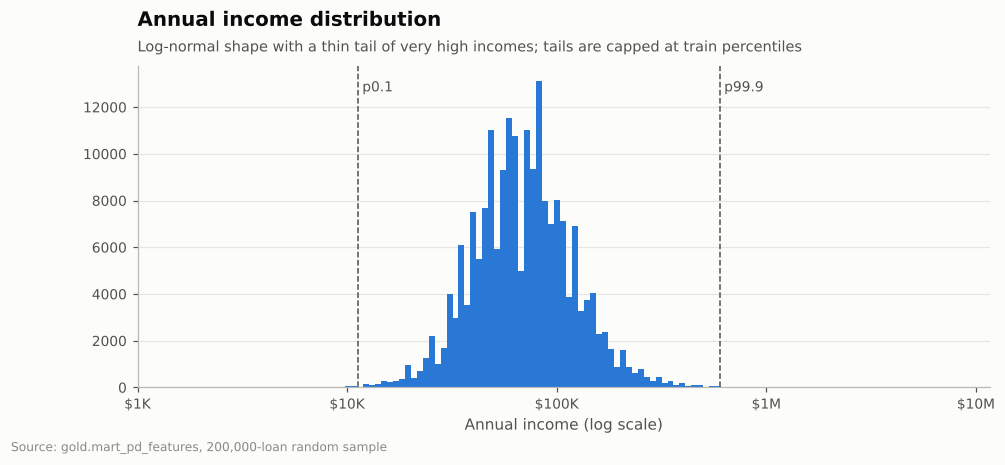

In [6]:
sample = con.execute("""select annual_income from gold.mart_pd_features
                         where annual_income > 0 using sample 200000 rows (reservoir, 42)""").df()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(np.log10(sample.annual_income), bins=120, color=viz.BLUE)
for q, label in [(0.001, "p0.1"), (0.999, "p99.9")]:
    v = np.log10(sample.annual_income.quantile(q))
    ax.axvline(v, color=viz.INK_2, lw=1, ls="--")
    ax.text(v, ax.get_ylim()[1] * 0.92, f" {label}", fontsize=9, color=viz.INK_2)
ax.set_xticks([3, 4, 5, 6, 7], ["$1K", "$10K", "$100K", "$1M", "$10M"])
ax.set_xlabel("Annual income (log scale)")
ax.set_title("Annual income distribution")
viz.subtitle(ax, "Log-normal shape with a thin tail of very high incomes; tails are capped at train percentiles")
viz.source(fig, "gold.mart_pd_features, 200,000-loan random sample")
plt.show()

**Finding:** income is log-normal. The median is USD 65K and 99.9% of borrowers earn under USD 600K, but a few report up to USD 10M. These could be real, but a handful of extreme values should not steer a model.

**Decision:** cap continuous variables at the 0.1th and 99.9th percentiles **of the training set** (winsorisation). The caps are learned on train and applied unchanged to validation, test and live data.

## 3. Completeness: what is missing, and why

Missing values are not all alike. A field can be missing because it was **not collected yet** (structural), because the **event never happened** (informative), or **at random**. Each needs a different treatment.

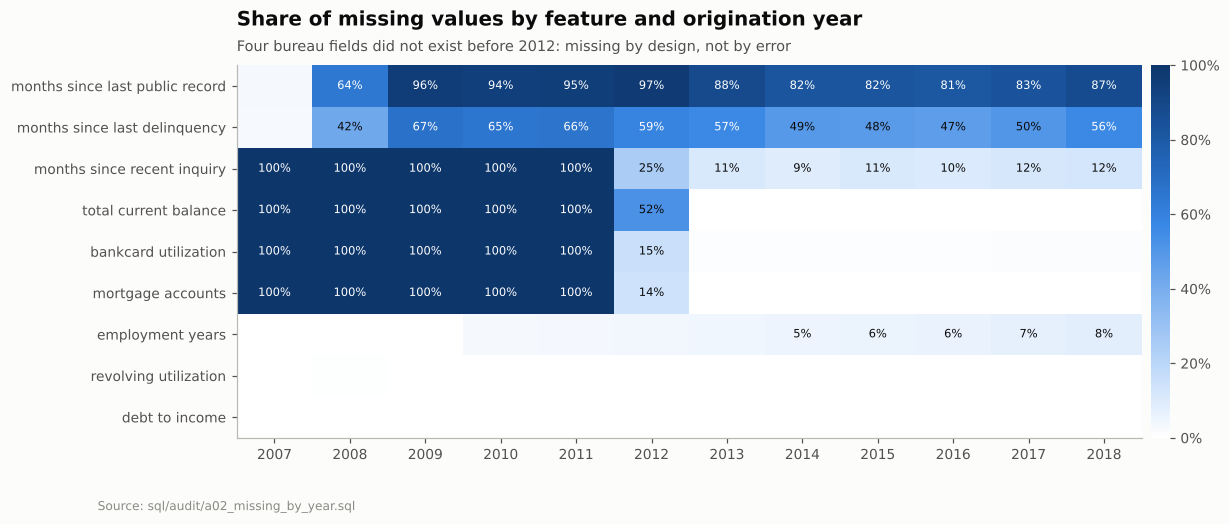

In [7]:
miss = con.execute((config.SQL_DIR / "audit" / "a02_missing_by_year.sql").read_text()).df()
grid = miss.pivot(index="feature", columns="issue_year", values="missing_share")
grid = grid.loc[grid.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 4.4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("seq", ["#ffffff"] + viz.SEQ_BLUE)
im = ax.imshow(grid.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index.str.replace("_", " "))
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.55 else viz.INK)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, format=plt.matplotlib.ticker.PercentFormatter(1))
cb.outline.set_visible(False)
ax.set_title("Share of missing values by feature and origination year")
viz.subtitle(ax, "Four bureau fields did not exist before 2012: missing by design, not by error")
viz.source(fig, "sql/audit/a02_missing_by_year.sql")
plt.show()

Three patterns stand out:

| Pattern | Fields | Cause | Decision |
|---|---|---|---|
| **Structural** | mortgage accounts, total current balance, bankcard utilisation, months since recent inquiry | Lending Club added these bureau attributes in 2012 | **Train on 2012 onwards.** This drops 39,786 loans (8.6% of train) but gives the model a consistent set of inputs. Imputing four years of non-existent bureau data would invent information. |
| **Informative** | months since last delinquency, months since last public record | Blank means the borrower *never* had one | Keep as missing and add a binary flag (`has_delinquency_history`, `has_public_record`). The WoE binning in notebook 05 gives "never" its own bin. |
| **Random, small** | employment years (5 to 8%), DTI, revolving utilisation (under 0.1%) | Not provided by the applicant | Missing flag for employment years. Median imputation (fitted on train) for the rest. |

Is the "informative" claim true? If a blank means "never delinquent", those borrowers should default less.

In [8]:
inf = con.execute("""
    select
        'Delinquency history'   as attribute,
        avg(target_bad_24m::int) filter (where months_since_last_delinquency is null)     as bad_rate_when_missing,
        avg(target_bad_24m::int) filter (where months_since_last_delinquency is not null) as bad_rate_when_present
    from gold.mart_pd_features where dataset_split = 'train' and is_full_bureau_era
    union all
    select 'Public record',
        avg(target_bad_24m::int) filter (where months_since_last_public_record is null),
        avg(target_bad_24m::int) filter (where months_since_last_public_record is not null)
    from gold.mart_pd_features where dataset_split = 'train' and is_full_bureau_era
    union all
    select 'Employment length',
        avg(target_bad_24m::int) filter (where employment_years is null),
        avg(target_bad_24m::int) filter (where employment_years is not null)
    from gold.mart_pd_features where dataset_split = 'train' and is_full_bureau_era
""").df()
inf["relative_risk"] = inf.bad_rate_when_missing / inf.bad_rate_when_present
inf.style.format({"bad_rate_when_missing": "{:.2%}", "bad_rate_when_present": "{:.2%}",
                  "relative_risk": "{:.2f}x"}).hide(axis="index")

attribute,bad_rate_when_missing,bad_rate_when_present,relative_risk
Delinquency history,8.98%,8.93%,1.01x
Public record,8.90%,9.33%,0.95x
Employment length,11.73%,8.82%,1.33x


**Partly confirmed, and the difference matters:**

- **Employment length not stated** is a genuine risk signal: those borrowers default about 1.3 times as often. The flag is kept as a feature.
- **No recorded delinquency or public record** barely changes the bad rate on its own. The intuitive story ("blank means never delinquent, so safer") does not hold strongly in this data, probably because Lending Club already screened out most borrowers with recent problems.

**Decision:** keep all three as flags anyway. They cost nothing, and their value is decided by the data in notebook 05 (Information Value) rather than by intuition. Intuitions that the data does not support are dropped there.

## 4. Timeliness and target maturity

In [9]:
tl = con.execute("""
    select dataset_split,
           min(issue_month)                  as first_issue_month,
           max(issue_month)                  as last_issue_month,
           count(*)                          as loans,
           count(target_bad_24m)             as loans_with_mature_label,
           avg(target_bad_24m::int)          as bad_rate_24m
    from gold.mart_pd_features
    group by 1 order by first_issue_month
""").df()
print(f"Snapshot date (last payment month in the data): {config.SNAPSHOT_DATE:%B %Y}")
tl.style.format({"loans": "{:,.0f}", "loans_with_mature_label": "{:,.0f}", "bad_rate_24m": "{:.2%}",
                 "first_issue_month": "{:%Y-%m}", "last_issue_month": "{:%Y-%m}"}).hide(axis="index")

Snapshot date (last payment month in the data): March 2019


dataset_split,first_issue_month,last_issue_month,loans,loans_with_mature_label,bad_rate_24m
train,2007-06,2014-12,"463,596","463,596",8.87%
validation,2015-01,2015-12,"421,095","421,095",10.70%
test_oot,2016-01,2016-12,"434,407","434,407",11.36%
monitoring,2017-01,2018-12,"938,821","96,779",10.09%


**Finding:** the target is mature for every loan in train, validation and test. In the monitoring population only Q1 2017 loans have reached 24 months, so that population is used for drift checks, with Q1 2017 as an early read on performance.

The bad rate rises from 8.9% (train, full-bureau era) to 10.7% (validation) to 11.4% (test). The model will be evaluated on a population that is **28% riskier** than the one it learned from. That is a hard but realistic test.

## 5. Leakage audit

A leaking feature is information that would not exist when Meridian makes the lending decision. The cell below measures how well each field alone separates good from bad loans (AUC, where 0.5 is random and 1.0 is perfect).

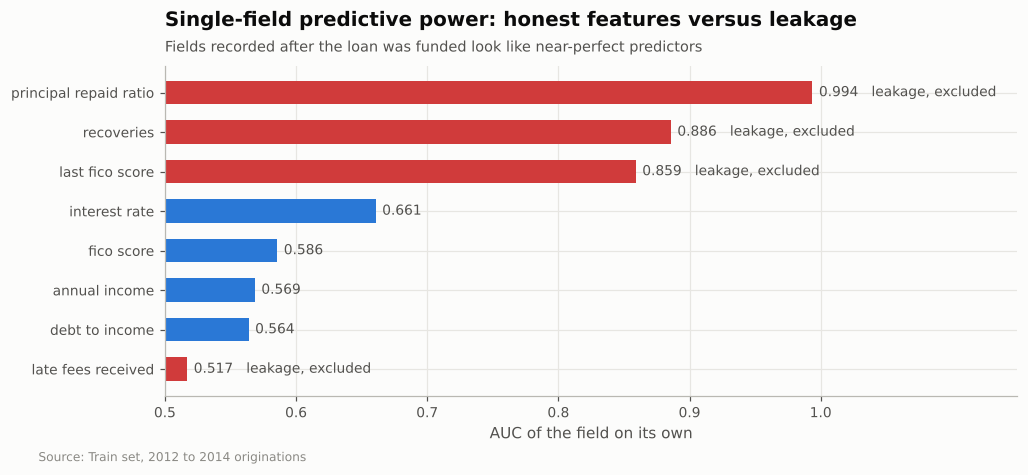

In [10]:
lk = con.execute(f"""
    select f.target_bad_24m::int as bad,
           b.total_rec_prncp / b.funded_amnt as principal_repaid_ratio,
           b.recoveries,
           b.last_fico_range_high          as last_fico_score,
           b.total_rec_late_fee            as late_fees_received,
           f.benchmark_interest_rate       as interest_rate,
           f.fico_score,
           f.annual_income,
           f.debt_to_income
    from gold.mart_pd_features f
    join '{config.BRONZE_DIR}/lending_club_loans.parquet' b on f.loan_id = try_cast(b.id as bigint)
    where f.dataset_split = 'train' and f.is_full_bureau_era
""").df()

post_origination = {"principal_repaid_ratio", "recoveries", "last_fico_score", "late_fees_received"}
rows = []
for col in lk.columns.drop("bad"):
    x = lk[col].fillna(lk[col].median())
    auc = roc_auc_score(lk.bad, x)
    rows.append({"field": col, "auc_alone": max(auc, 1 - auc),
                 "known_at_application": col not in post_origination})
leak = pd.DataFrame(rows).sort_values("auc_alone")

fig, ax = plt.subplots(figsize=(10, 3.9))
colors = [viz.BLUE if k else viz.CRITICAL for k in leak.known_at_application]
ax.barh(leak.field.str.replace("_", " "), leak.auc_alone - 0.5, left=0.5, color=colors, height=0.6)
for y, (v, k) in enumerate(zip(leak.auc_alone, leak.known_at_application)):
    ax.text(v + 0.005, y, f"{v:.3f}" + ("" if k else "   leakage, excluded"), va="center", fontsize=9, color=viz.INK_2)
ax.set_xlim(0.5, 1.15)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.axvline(0.5, color=viz.NEUTRAL, lw=1)
ax.grid(axis="x", color=viz.GRID)
ax.set_xlabel("AUC of the field on its own")
ax.set_title("Single-field predictive power: honest features versus leakage")
viz.subtitle(ax, "Fields recorded after the loan was funded look like near-perfect predictors")
viz.source(fig, "Train set, 2012 to 2014 originations")
plt.show()

**Finding:** a model allowed to see `principal_repaid_ratio` would score an AUC of 0.99 and be useless in production. The ratio simply records that the borrower stopped paying. The most predictive honest field, the interest rate, reaches only 0.66.

**Decision:** 20 post-origination fields are listed in `config.LEAKAGE_COLUMNS` and never enter `mart_pd_features`. The dbt test `assert_no_leakage_in_pd_features` fails the build if one ever does. Lending Club's own grade and interest rate are also kept *out* of the model. They are the output of Lending Club's model, so Meridian's model is benchmarked against them instead of built on them.

## 6. Data quality scorecard and decision log

In [11]:
scorecard = pd.DataFrame([
    ("Uniqueness",   "Duplicate loan ids",                                   0,      "Pass",     "None needed"),
    ("Uniqueness",   "Source footer rows without a loan id",                 33,     "Low",      "Removed in staging; reconciliation test"),
    ("Consistency",  "FICO bounds, credit-line dates, funded vs requested",  0,      "Pass",     "None needed"),
    ("Consistency",  "Instalment differs from annuity formula by over 1%",   714,    "Low",      "Kept; 0.03% of loans, likely post-issue modifications"),
    ("Validity",     "Zero income (1,667) or DTI above 100% (2,561), all joint applications", None,   "High",     "Fixed in warehouse: household figures for joint apps"),
    ("Validity",     "Extreme income, balances and ratios",                  None,   "Medium",   "Winsorise at train p0.1 / p99.9"),
    ("Validity",     "Home ownership ANY / NONE / OTHER",                    1232,   "Low",      "Grouped into OTHER"),
    ("Completeness", "Bureau fields absent before 2012 (structural)",        39786,  "High",     "Train on 2012+ originations"),
    ("Completeness", "Months since delinquency / public record (informative)", None, "Medium",   "Keep missing, add flags, own WoE bin"),
    ("Completeness", "Employment years missing (informative)",               None,   "Medium",   "Missing flag; own WoE bin"),
    ("Completeness", "DTI, utilisation small gaps (random)",                 None,   "Low",      "Median imputation fitted on train"),
    ("Timeliness",   "Immature outcomes for 2017 to 2018 loans",              938821, "High",     "24-month target; monitoring population"),
    ("Leakage",      "20 post-origination fields",                           None,   "Critical", "Excluded by construction; dbt test"),
    ("Leakage",      "Lending Club grade and rate (another model's output)", None,   "High",     "Benchmark only, not a feature"),
], columns=["dimension", "check", "rows_affected", "severity", "decision"])
scorecard.to_csv(REPORTS / "data_audit_scorecard.csv", index=False)
scorecard.style.format({"rows_affected": lambda v: "" if pd.isna(v) else f"{v:,.0f}"}).hide(axis="index")

dimension,check,rows_affected,severity,decision
Uniqueness,Duplicate loan ids,0,Pass,None needed
Uniqueness,Source footer rows without a loan id,33,Low,Removed in staging; reconciliation test
Consistency,"FICO bounds, credit-line dates, funded vs requested",0,Pass,None needed
Consistency,Instalment differs from annuity formula by over 1%,714,Low,"Kept; 0.03% of loans, likely post-issue modifications"
Validity,"Zero income (1,667) or DTI above 100% (2,561), all joint applications",,High,Fixed in warehouse: household figures for joint apps
Validity,"Extreme income, balances and ratios",,Medium,Winsorise at train p0.1 / p99.9
Validity,Home ownership ANY / NONE / OTHER,"1,232",Low,Grouped into OTHER
Completeness,Bureau fields absent before 2012 (structural),"39,786",High,Train on 2012+ originations
Completeness,Months since delinquency / public record (informative),,Medium,"Keep missing, add flags, own WoE bin"
Completeness,Employment years missing (informative),,Medium,Missing flag; own WoE bin


## 7. Summary

The data is **fit for purpose** once five issues are handled. None of them would have been visible from summary statistics alone:

1. **Joint applications** looked like zero-income borrowers. Fixed at the source in SQL.
2. **Bureau fields did not exist before 2012.** The model trains on 2012 to 2014, a consistent and still large sample (423,810 loans).
3. **Missing values carry meaning.** "Never delinquent" and "employment not stated" are kept as signals.
4. **Twenty fields leak the outcome.** They are excluded by construction and guarded by a test.
5. **The test population is 28% riskier than train.** The out-of-time evaluation will be demanding.

**Next:** notebook 03 implements every "learned" decision as a reusable, train-fitted cleaning pipeline.